# Task Title: Vector Space Semantics for Similarity between EastEnders Characters

In this assignment, you will be creating a vector representation of a document containing lines spoken by a character in the EastEnders script data (i.e. from the file `training.csv`), then improving that representation such that each character vector is maximally distinguished from the other character documents. This distinction is measured by how well a simple information retrieval classification method can select documents from validation and test data as belonging to the correct class of document (i.e. deciding which character spoke the lines by measuring the similarity of those character document vectors to those built in training).

As the lines are not evenly distributed in terms of frequency, this coursework stipulates you can only use a maximum of the first **300 lines** of each character in the training data `training.csv` to create the training documents and a maximum of the first **50 lines** in the validation and test data (from `val.csv` and `test.csv`). This makes it more challenging, as the number of lines spoken by a character can't be used directly or otherwise as a feature.

A simple vector representation for each character document is done for you to start with in this code, as is the pipeline of similarity-based information retrieval evaluation. You need to improve the character vector representations by pre-processing, feature extraction and transformation techniques, as per Question 1-5 below, which you need to complete as instructed.

**Refer to the material in units 8-9 for conceptual background.**

In [35]:
!pip install nltk
!pip install gensim


[notice] A new release of pip is available: 24.1.2 -> 25.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.1.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [36]:
import string
import re
import numpy as np
from numpy.linalg import norm
import pandas as pd
from collections import Counter, OrderedDict
import seaborn as sns
import matplotlib.pyplot as plt
import math
import nltk

# Download required NLTK data, useful packages 
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')
    
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')
try:
    nltk.data.find('taggers/avg_perceptron_tagger_eng')
except LookupError:
    nltk.download('averaged_perceptron_tagger_eng')
try:
    nltk.data.find('corpora/wordnet')
except LookupError:
    nltk.download('wordnet')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize 
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.feature_extraction import DictVectorizer

%matplotlib inline
pd.options.display.max_colwidth=500

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/jovyan/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /home/jovyan/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [37]:
# Initialisee NLTK components
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Load in training data and display in pandas dataframe
train_path = 'training.csv'
train_data = pd.read_csv(train_path, delimiter="\t", skip_blank_lines=True)
val_path = 'val.csv'
val_data = pd.read_csv(val_path, delimiter="\t", skip_blank_lines=True)
test_path = 'test.csv'
test_data = pd.read_csv(test_path, delimiter="\t", skip_blank_lines=True)

# Inspect the data
print("\nTraining data shape:", train_data.shape)
print("\nFirst few rows:")
train_data.head()


Training data shape: (14013, 6)

First few rows:


,Episode,Scene,Scene_info,Character_name,Line,Gender
0,1350,1,DESERTED CAR PARK EXT NIGHT,SHIRLEY,"Look at ya, not a mark on ya. And you think you're an unlucky man.",FEMALE
1,1350,1,DESERTED CAR PARK EXT NIGHT,OTHER,Shirl...,MALE
2,1350,2,R&R INT NIGHT,JACK,Oi. Where have you been? Huh? What were the texts about?,MALE
3,1350,2,R&R INT NIGHT,RONNIE,Nothing. Nothing. I'll be with you in two minutes yeah?,FEMALE
4,1350,2,R&R INT NIGHT,JACK,"Well I've got mates here I wanted to have a chat with them, instead I've been serving behind the bar.",MALE


In [38]:
# Contraction mapping for expanding common English contractions
# This helps normalising the text e.g. from words like 'haven't' to 'have not' which helps with processing
# Contraction mapping for expanding common English contractions
# This helps normalize text by converting "don't" → "do not", etc.
CONTRACTION_MAP = {
    "ain't": "am not",
    "aren't": "are not",
    "can't": "cannot",
    "can't've": "cannot have",
    "could've": "could have",
    "couldn't": "could not",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'll": "he will",
    "he's": "he is",
    "how'd": "how did",
    "how'll": "how will",
    "how's": "how is",
    "i'd": "i would",
    "i'll": "i will",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it'd": "it would",
    "it'll": "it will",
    "it's": "it is",
    "let's": "let us",
    "ma'am": "madam",
    "might've": "might have",
    "mightn't": "might not",
    "must've": "must have",
    "mustn't": "must not",
    "needn't": "need not",
    "shan't": "shall not",
    "she'd": "she would",
    "she'll": "she will",
    "she's": "she is",
    "should've": "should have",
    "shouldn't": "should not",
    "that'd": "that would",
    "that's": "that is",
    "there'd": "there would",
    "there's": "there is",
    "they'd": "they would",
    "they'll": "they will",
    "they're": "they are",
    "they've": "they have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'll": "we will",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what'll": "what will",
    "what're": "what are",
    "what's": "what is",
    "what've": "what have",
    "where'd": "where did",
    "where's": "where is",
    "who'll": "who will",
    "who's": "who is",
    "won't": "will not",
    "wouldn't": "would not",
    "you'd": "you would",
    "you'll": "you will",
    "you're": "you are",
    "you've": "you have"
}

# Expands contractions in text for better word matching
def expand_contractions(text, contraction_map=CONTRACTION_MAP):
    """
    Expand contractions in the text for better word matching
    """
    # Create regex patterns that matches with any contraction in the library 
    contractions_pattern = re.compile('({})'.format('|'.join(contraction_map.keys())), flags=re.IGNORECASE|re.DOTALL)

    # Helper function to expand a matched contraction
    def expand_match(contraction):
        match = contraction.group(0)
        first_char = match[0]
        expanded = contraction_map.get(match.lower())

        if expanded is None:
            return match
        else:
            # Preserve capitalisation of the first character
            if first_char.isupper():
                return expanded[0].upper() + expanded[1:]
            else:
                return expanded

    # Expanded text that has been matched by the keys in the library
    expanded_text = contractions_pattern.sub(expand_match, text)
    return expanded_text

In [39]:
# Define n-grams to capture word sequences and preserve context 
def get_ngrams(tokens, n=2):
    """
    Generates n-gram from a list of token, bigrams that converts words like "very", "good" to "very_good" as the combination could mean something different
    """
    ngrams = []
    for i in range(len(tokens) - n + 1):
        ngram = "_".join(tokens[i:i+n])
        ngrams.append(ngram) # Append all ngram context words into ngrams variable
    return ngrams

In [40]:
# Extract character n-grams features
def extract_ngrams_features(text, n=3):
    """
    Technique 3: Use character level ngrams to capture accent patterns e.g. innit or wanna or gonna

    """
    # Remove space and special markers for character n-grams analysis
    clean_text = text.replace('_eol_', '').replace(' ', '').lower()
    char_grams = []
    for i in range(len(clean_text) - n + 1):
        ngram = clean_text[i:i+n]
        # Only include alphabetic character n-grams
        if ngram.isalpha():
            char_grams.append(ngram)
    return Counter(char_grams)

In [41]:
def pre_process_configurable(character_text, config):
    """Pre-process all the concatenated lines of a character, 
    using tokenization, spelling normalization and other techniques.
    
    Initially just a tokenization on white space. Improve this for Q1.
    
    ::character_text:: a string with all of one character's lines
    """
    text = character_text
    # Technique 1: Convert all words to lowercase for normalisation and better process
    if config.get('lowercase', True):
        text = text.lower()
    
    # Technique 2: Handle contractions like converting 'Haven't' to 'Have not'
    if config.get('expand_contractions', True):
        text = expand_contractions(text)

    # Technique 3: Tokenise the text to individual unique words -> tokens
    tokens = word_tokenize(text)   # just a simple tokenisation, to be replaced

    # Technique 4: Remove and handle punctuations in the text but keep ("!" or "?") for context
    if config.get('remove_punctuation', True):
        tokens = [token for token in tokens if token not in string.punctuation]

    # Technique 5: Remove and reduce common words in text using the 'stopwords' library in nltk 
    if config.get('remove_stopwords', True):
        tokens = [token for token in tokens if token not in stop_words or token == '_eol_']
    
    # Technique 6: Apply Lemmatisation - reduce words to their base form 
    if config.get('lemmatize', True):
        tokens = [lemmatizer.lemmatize(token) for token in tokens] # For loop to go through the list of tokens (words) and convert all the words to their base form

    # Technique 7: Filter the tokens and remove very short tokens 
    min_len = config.get('min_token_length', 2)
    tokens = [token for token in tokens if len(token) > min_len]
        
    if config.get('use_bigrams', True):
        bigrams = get_ngrams(tokens, n=2)
        tokens = tokens + bigrams
        
    if config.get('use_trigrams', False):
        trigrams = get_ngrams(tokens, n=3) # Function for extracting trigrams with more filters for capturing accent/slang features
        tokens = tokens + trigrams

    # Final tokens after preprocessing 
    return tokens


In [42]:
# Create one document per character
def create_character_document_from_dataframe(df, max_line_count):
    """Returns a dict with the name of the character as key,
    their lines joined together as a single string, with end of line _eol_
    markers between them

    Improve this for Q2
    
    ::max_line_count:: the maximum number of lines to be added per character

    Enhancements for Q2 

    New Features Extracted
    1. Line count - how much the character speaks 
    2. Individual line list - for sentence level analysis
    3. Gender Info - male / female (demographic feature)

    Purpose - goes beyond text concatensation, we now try to preserve structure 
    that allows us to compute character specific linguistic features
    """
    character_docs = {}
    
    for line, name, gender in zip(df.Line, df.Character_name, df.Gender):
        #remove the empty lines
        if (isinstance(line, float) and math.isnan(line)) or line == "":
            continue
        # Initialise character entry
        if name not in character_docs:
            character_docs[name] = {
                'text': "",
                'lines': [],
                'gender': gender,
                'line_count': 0
            }

        # Check max line limit
        if character_docs[name]['line_count'] >= max_line_count:
            continue

        # Store both concatenated text and individual lines
        character_docs[name]['text'] += str(line)   + " _eol_ "  # adding an end-of-line token
        character_docs[name]['lines'].append(str(line))
        character_docs[name]['line_count'] += 1
    
    print("lines per character: ")
    for name in sorted(character_docs.keys()):
        print(f"{name}: {character_docs[name]['line_count']} lines")
    return character_docs

In [43]:
# print out the number of words each character has in the training set
# only use the first 300 lines of each character
train_character_docs = create_character_document_from_dataframe(train_data, max_line_count=300)
print('Num. Characters: ',len(train_character_docs.keys()),"\n")
total_words = 0
for name in train_character_docs.keys():
    print(name, 'Number of Words: ',len(train_character_docs[name]['text']))
    total_words += len(train_character_docs[name]['text'])
print("total words", total_words)

lines per character: 
CHRISTIAN: 300 lines
CLARE: 300 lines
HEATHER: 300 lines
IAN: 300 lines
JACK: 300 lines
JANE: 300 lines
MAX: 300 lines
MINTY: 300 lines
OTHER: 300 lines
PHIL: 300 lines
RONNIE: 300 lines
ROXY: 300 lines
SEAN: 300 lines
SHIRLEY: 300 lines
STACEY: 300 lines
TANYA: 300 lines
Num. Characters:  16 

SHIRLEY Number of Words:  16078
OTHER Number of Words:  14329
JACK Number of Words:  19241
RONNIE Number of Words:  15763
TANYA Number of Words:  17611
SEAN Number of Words:  14988
ROXY Number of Words:  16280
MAX Number of Words:  20452
IAN Number of Words:  18558
JANE Number of Words:  16782
STACEY Number of Words:  16891
PHIL Number of Words:  16273
HEATHER Number of Words:  17362
MINTY Number of Words:  17192
CHRISTIAN Number of Words:  17691
CLARE Number of Words:  19173
total words 274664


In [44]:
# Stylometric features of each of the characters
def extract_stylometric_features(text, lines_list):
    """
    Technique 1: Stylometric (speaking-style) Features 
    Extracts stylometric features about how the characters speak, not just what they say

    Features Extracted:
    avg_sentence_length - some characters speak in a long sentence whereas some are very short
    vocabulary_richness - Unique words/total words
    avg_word_length - some characters use longer words than others
    utterance_count - how many separate things they say 

    Educated character vs Simpler character
    """
    features = {}
    # Tokenise for analysis 
    words = text.lower().split()
    words = [w for w in words if w != '_eol_' and len(w) > 0]
    if len(words) == 0:
        return {
            'avg_sentence_length': 0,
            'vocabulary_richness': 0,
            'avg_word_length': 0,
            'utterance_count': 0
        }
    # Calculate raw values 
    avg_sentence_length = len(words) / max(len(lines_list), 1)
    vocab_richness = len(set(words)) / len(words)
    avg_word_length = np.mean([len(w) for w in words])
    utterance_count = len(lines_list)
    
    # Features 1: Average sentence length and utterance length
    # Some characters speak tersely ("Yes." "No." "Fine."), others give speeches
    features['avg_sentence_length'] = avg_sentence_length
    # Feature 2: Vocababulary richness
    # Unique words / total words 
    # High ratio means varied vocabulary / low means simple vocabular
    unique_words = len(set(words))
    features['vocabulary_richness'] = vocab_richness
    # Feature 3: Average word length 
    features['avg_word_length'] = avg_word_length
    # Feature 4: Number of utterance
    # How often they speak up
    # Utterances: should be 300 for training
    features['utterance_count'] = utterance_count

    return features

In [45]:
# Punctuation pattern features
def extract_punctuation_features(text):
    """
    Technique 2: Punctuation Features

    Each character has their own emotional features and punctuations are good indicators for that

    Features:
    1. exclamation_ratio - Excited/angry characters use more !
    2. question_ratio - Inquisitive characters ask more questions
    3. ellipsis_ratio - Hesitant/thoughtful speech patterns (...)

    Punctuation reveals emotions of the characters
    """
    features = {}
    text = str(text)
    # Count punctuation marks
    exclamation_count = text.count('!')
    question_count = text.count('?')
    ellipsis_count = text.count('...')
    period_count = text.count('.')
    # Total sentences (estimate)
    total_sentences = max(exclamation_count + question_count + period_count, 1)
    # Feature 1 - Exclamation ratio 
    features['exclamation_ratio'] = exclamation_count / total_sentences 
    # Feature 2 - Question ratio
    features['question_ratio'] = question_count / total_sentences
    # Feature 3 - Ellipsis ratio
    features['ellipsis_ratio'] = ellipsis_count / total_sentences

    return features 

In [46]:
# Part-of-speech (POS) Features
def extract_pos_features(processed_tokens):
    """
    Technique 3: Part-of-speech (POS) Features

    Analyses grammarical patterns, what types of words each of the characters use

    Features:
    1. noun_ratio - Action-oriented vs. descriptive speech
    2. verb_ratio - Active characters use more verbs
    3. adjective_ratio - Descriptive characters use more adjectives
    4. pronoun_ratio - Self-focused (I, me) vs. other-focused (you, they)
    """
    # Filter out n-grams and special tokens for POS tagging 
    word_tokens = [t for t in processed_tokens if '_' not in t and t != '_eol_']

    if len(word_tokens) == 0:
        return {
            'noun_ratio': 0,
            'verb_ratio': 0,
            'adjective_ratio': 0,
            'pronoun_ratio': 0
        }

    # Get POS tags
    pos_tags = nltk.pos_tag(word_tokens)
    pos_count = Counter([tag for word, tag in pos_tags])
    # Total length of tags
    total_tags = len(pos_tags)
    # Feature 1: Noun ratio
    noun_count = sum([pos_count.get(tag, 0) for tag in ['NN', 'NNS', 'NNP', 'NNPS']])
    # Feature 2: Verb ratio 
    verb_count = sum([pos_count.get(tag, 0) for tag in ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ']])
    # Feature 3: Adjective ratio 
    adj_count = sum([pos_count.get(tag, 0) for tag in ['JJ', 'JJR', 'JJS']])
    # Feature 4: Pronoun ratio 
    pronoun_count = sum([pos_count.get(tag, 0) for tag in ['PRP', 'PRP$']])

    return {
        'noun_ratio': noun_count / total_tags,
        'verb_ratio': verb_count / total_tags,
        'adj_ratio': adj_count / total_tags,
        'pronoun_count': pronoun_count / total_tags
    }

In [47]:
def extract_function_word_features(processed_tokens):
    """
    Function words that reveal syntactic preferences
    """
    # Common function words that vary by character
    function_words = {
        'articles': ['the', 'a', 'an'],
        'prepositions': ['in', 'on', 'at', 'to', 'for', 'with', 'from', 'by'],
        'conjuctions': ['and', 'but', 'or', 'so', 'yet', 'because'],
        'pronouns': ['i', 'you', 'he', 'she', 'it', 'we', 'they', 'me', 'him', 'her'],
        'auxiiaries': ['am', 'is', 'are', 'was', 'were', 'be', 'being', 'been', 'do', 'does', 'did', 'have', 'has', 'had', 'can', 'could', 'may', 'might', 'will', 'would', 'shall']
    }
    word_tokens = [t.lower() for t in processed_tokens if '_' not in t]
    total_words = len(word_tokens)

    if total_words == 0:
        return {f"{cat}_ratio": 0 for cat in function_words}

    features = {}
    for category, words in function_words.items():
        count = sum(1 for token in word_tokens if token in words)
        features[f"{category}_ratio"] = count / total_words
        
    return features

In [48]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

def train_vec_model(corpus_with_features, vector_size = 50):
    """
    Train Doc2Vec on the character documents
    """
    tagged_docs = [
        TaggedDocument(words=tokens, tags=[name]) for name, token, _ in corpus_with_features
    ]
    model = Doc2Vec(
        tagged_docs,
        vector_size = vector_size,
        window = 5,
        min_count = 2,
        workers = 4,
        epochs = 40
                   )
    return model
    # Use the vec
    doc2vec_model = train_vec_model(training_corpus_with_features)
    # Then extract features by updating the extra_features {}
    doc_vector = doc2vec_model.infer_vector(processed_tokens)
    for i , val in enumerate(doc_vector):
        extra_features[f'doc2vec_{i}'] = val

In [49]:
def extract_features_configurable(original_text, lines_list, processed_tokens, config):
    """
    Configurable features extraction
    """
    extra_features = {}
    # Feature 1: Stylometric 
    if config.get('use_stylometric', True):
        stylometric = extract_stylometric_features(original_text, lines_list)
        extra_features.update(stylometric)
    # Feature 2: Punctuation
    if config.get('use_punctuation', True):
        punctuation = extract_punctuation_features(original_text)
        extra_features.update(punctuation)
    # Feature 3: Pos
    if config.get('use_pos', True):
        pos_features = extract_pos_features(processed_tokens)
        extra_features.update(pos_features)
    # Feature 4: Character N-grams
    if config.get('use_char_ngrams', False):
        type_of_ngrams = config.get('char_ngrams_n', 3)
        top_k = config.get('char_gram_top_k', 50)
        # Extract character-level n-grams
        char_ngrams = extract_ngrams_features(original_text, n=type_of_ngrams)
        # Get max count for nomalisation 
        max_count = max(char_ngrams.values() if char_ngrams else 1)
        for ngram, count in char_ngrams.most_common(top_k):
            # Normalise 0-1 range to match with TF-IDF scale
            normalised_count = count / max_count
            extra_features[f"character_trigrams_{ngram}"] = normalised_count
        print(f"Character Trigrams: {len(char_ngrams)} unique trigrams")

    # Feature 5: Function words 
    if config.get('use_function_words', True):
        func_words = extract_function_word_features(processed_tokens)
        extra_features.update(func_words)
        

    return extra_features

In [50]:
def to_feature_vector_dictionary(character_doc, extra_features):
    """Converts a list of pre-processed tokens and extra features
    to a Dictionary as a function of the tokens.
    
    Initially just a simple count. Improve this for Q2.
    
    ::character_doc:: a list of pre-processed tokens
    ::extra_features:: any extra features for the character to be added to feature vector dict

    Enhancement for Q2

    Converts the preprocessed tokens with the enhanced features extracted into a comprehensive dictionary

    The dict now contains:
    1. Word-level features (bag of words with counts)
    2. Stylometric features (speaking style statistics)
    3. Punctuation features (indicators on emotional patterns)
    4. POS features (grammatical patterns)
    5. Character n-gram features (accent/dialect patterns)
    """
    # Starting with word counts
    counts = Counter(character_doc)  # for now a simple count, counts the occurrences of each token
    feature_dict = dict(counts) 
    
    # add the extra features, for now just adding one count for each extra feature
    # Add all extra linguistic features
    for feature_name, feature_value in extra_features.items():
        # Prefix feature names to avoid mixing with word tokens
        feature_key = f"Feature_{feature_name}"
        feature_dict[feature_key] = feature_value
    return feature_dict  

In [51]:
# Global vectorisers and transformers
corpusVectorizer = DictVectorizer()   # corpusVectorizor which will just produce sparse vectors from feature dicts
tfidfTransformer = TfidfTransformer()

In [52]:
# Create the feature matrix with TF-IDF weighting
print("Creating TF-IDF Weighted Feature Matrix...")

# Step 3: Create feature matrix with tf-idf weights applied

# Need to update the to_feature_vector_dictionary calls to add on extra features
def create_document_matrix_with_features(corpus_with_features, fitting=False):
    """
    Create a document matrix using processed tokens and extra features
    """
    feature_dicts = [to_feature_vector_dictionary(doc, extra_feats) for name, doc, extra_feats in corpus_with_features]

    if fitting:
        corpusVectorizer.fit(feature_dicts)
        count_matrix = corpusVectorizer.transform(feature_dicts)
        tfidfTransformer.fit(count_matrix)
        doc_feature_matrix = tfidfTransformer.transform(count_matrix)
    else: 
        count_matrix = corpusVectorizer.transform(feature_dicts)
        doc_feature_matrix = tfidfTransformer.transform(count_matrix)

    return doc_feature_matrix

print("Weighted Feature Matrix Complete!")

Creating TF-IDF Weighted Feature Matrix...
Weighted Feature Matrix Complete!


In [53]:
def compute_cosine_similarity(v1, v2):
    """Takes a pair of vectors v1 and v2 (1-d arrays e.g. [0, 0.5, 0.5])
    returns the cosine similarity between the vectors
    """
    
    # compute cosine similarity manually
    manual_cosine_similarity = np.dot(v1, v2)  /(norm(v1) * norm(v2))
    
    return manual_cosine_similarity

In [54]:
def compute_IR_evaluation_scores(train_feature_matrix, test_feature_matrix, train_labels, test_labels):
    """
    Computes an information retrieval based on training data feature matrix and test data feature matrix
    returns 4-tuple:
    ::mean_rank:: mean of the ranking of the target document in terms of similarity to the query/test document
    1 is the best possible score.
    ::mean_cosine_similarity:: mean cosine similarity score for the target document vs. the test document of the same class
    ::accuracy:: proportion of test documents correctly classified
    ::df:: a data frame with all the similarity measures of the test documents vs. train documents
    
    params:
    ::train_feature_matrix:: a numpy matrix N x M shape where N = number of characters M = number of features
    ::test_feature_matrix::  a numpy matrix N x M shape where N = number of characters M = number of features
    ::train_labels:: a list of character names for the training data in order consistent with train_feature_matrix
    ::test_labels:: a list of character names for the test data in order consistent with test_feature_matrix
    """
    # Evaluate character identification performance
    rankings = []
    all_cosine_similarities = []
    pairwise_cosine_similarity = []
    pairs = []
    correct = 0
    for i, target in enumerate(test_labels):
        # compare the left out character against the mean
        idx = i 
        fm_1 = test_feature_matrix.toarray()[idx]
        all_sims = {}
        # print("target:", target)
        for j, other in enumerate(train_labels):
            fm_2 = train_feature_matrix.toarray()[j]
            manual_cosine_similarity = compute_cosine_similarity(fm_1, fm_2)
            pairs.append((target, other))
            pairwise_cosine_similarity.append(manual_cosine_similarity)
            if other == target:
                all_cosine_similarities.append(manual_cosine_similarity)
            all_sims[other] = manual_cosine_similarity

            # print(target, other, manual_cosine_similarity)
        sorted_similarities = sorted(all_sims.items(),key=lambda x:x[1],reverse=True)
        # print(sorted_similarities)
        ranking = {key[0]: rank for rank, key in enumerate(sorted_similarities, 1)}
        # print("Ranking for target", ranking[target])
        if ranking[target] == 1:
            correct += 1
        rankings.append(ranking[target])
        # print("*****")
    mean_rank = np.mean(rankings)
    mean_cosine_similarity = np.mean(all_cosine_similarities)
    accuracy = correct/len(test_labels)
    print("mean rank", np.mean(rankings))
    print("mean cosine similarity", mean_cosine_similarity)
    print(correct, "correct out of", len(test_labels), "/ accuracy:", accuracy )
    
    # get a dafaframe showing all the similarity scores of training vs test docs
    df = pd.DataFrame({'doc1': [x[0] for x in pairs], 'doc2': [x[1] for x in pairs],
                       'similarity': pairwise_cosine_similarity})

    # display characters which are most similar and least similar
    df.loc[[df.similarity.values.argmax(), df.similarity.values.argmin()]]
    return (mean_rank, mean_cosine_similarity, accuracy, df)

In [55]:
def plot_heat_map_similarity(df):
    """Takes a dataframe with header 'doc1, doc2, similarity'
    Plots a heatmap based on the similarity scores.
    """
    test_labels =  sorted(list(set(df.sort_values(['doc1'])['doc1'])))
    # add padding 1.0 values to either side
    cm = [[1.0,] * (len(test_labels)+2)]
    for target in test_labels:
        new_row = [1.0]
        for x in df.sort_values(['doc1', 'doc2'])[df['doc1']==target]['similarity']:
            new_row.append(x)
        new_row.append(1.0)
        cm.append(new_row)
    cm.append([1.0,] * (len(test_labels)+2))
    #print(cm)
    labels = [""] + test_labels + [""]
    fig = plt.figure(figsize=(20,20))
    ax = fig.add_subplot(111)
    cax = ax.matshow(cm)
    plt.title('Similarity matrix between documents as vectors')
    fig.colorbar(cax)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels( labels, rotation=45)
    ax.set_yticklabels( labels)

    for i in range(len(cm)):
        for j in range(len(cm)):

            text = ax.text(j, i, round(cm[i][j],3),
                           ha="center", va="center", color="w")

    plt.xlabel('Training Vector Doc')
    plt.ylabel('Test Vector Doc')
    #fig.tight_layout()
    plt.show()

In [56]:
def grid_search_q1(param_grid, train_data, val_data):
    """
    Perform grid search over Q1 preprocessing parameters.
    
    Args:
        param_grid: Dict of parameter options
        train_data: Training dataframe
        val_data: Validation dataframe
        
    Returns:
        DataFrame with results for each configuration
    """
    from itertools import product
    
    results = []
    
    # Generate all combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    
    print(f"Testing {np.prod([len(v) for v in param_values])} configurations...")
    
    for i, combination in enumerate(product(*param_values)):
        config = dict(zip(param_names, combination))
        
        print(f"\n{'='*70}")
        print(f"Configuration {i+1}: {config}")
        print(f"{'='*70}")
        
        # Create character documents
        train_char_docs = create_character_document_from_dataframe(train_data, max_line_count=300)
        val_char_docs = create_character_document_from_dataframe(val_data, max_line_count=50)
        
        # Build training corpus with this config
        training_corpus = []
        for name in sorted(train_char_docs.keys()):
            char_data = train_char_docs[name]
            original_text = char_data['text']
            processed_tokens = pre_process_configurable(original_text, config)
            training_corpus.append((name, processed_tokens, {}))
        
        train_labels = [name for name, doc, feats in training_corpus]
        
        # Build validation corpus
        val_corpus = []
        for name in sorted(val_char_docs.keys()):
            char_data = val_char_docs[name]
            original_text = char_data['text']
            processed_tokens = pre_process_configurable(original_text, config)
            val_corpus.append((name, processed_tokens, {}))
        
        val_labels = [name for name, doc, feats in val_corpus]
        
        # Create feature matrices
        training_matrix = create_document_matrix_with_features(training_corpus, fitting=True)
        val_matrix = create_document_matrix_with_features(val_corpus, fitting=False)
        
        # Evaluate
        mean_rank, mean_cos_sim, accuracy, df = compute_IR_evaluation_scores(
            training_matrix, val_matrix, train_labels, val_labels
        )
        
        # Store results
        result = {**config, 'mean_rank': mean_rank, 'accuracy': accuracy}
        results.append(result)
        
        print(f"Mean Rank: {mean_rank:.2f}, Accuracy: {accuracy:.2%}")
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values('mean_rank')
    
    return results_df

In [57]:

# Q1 GRID SEARCH: Preprocessing Parameters - Finding the Best Parameters For Q2

print("\n" + "="*70)
print("Q1: GRID SEARCH FOR PREPROCESSING PARAMETERS")
print("="*70 + "\n")

# Define parameter grid for Q1
q1_param_grid = {
    'lowercase': [True],  # Always True (standard practice)
    'expand_contractions': [True],  # Always True (standard practice)
    'remove_punctuation': [True],
    'remove_stopwords': [True, False],  # Test both
    'lemmatize': [True, False],  # Test both
    'min_token_length': [1, 2, 3],  # Test different thresholds (Getting rid of short and uninformative words)
    'use_bigrams': [True, False],  # Test with/without Bigrams
    'use_trigrams': [False]  # Test with/without Trigrams
}

# Run grid search
q1_results = grid_search_q1(q1_param_grid, train_data, val_data)

# Display results
print("\n" + "="*70)
print("Q1 GRID SEARCH RESULTS")
print("="*70)
print(q1_results.head(10))

# Save results
q1_results.to_csv('q1_grid_search_results.csv', index=False)

# Get best configuration
best_q1_config = q1_results.iloc[0].to_dict()
print("\n" + "="*70)
print("BEST Q1 CONFIGURATION:")
print("="*70)
for param, value in best_q1_config.items():
    if param not in ['mean_rank', 'accuracy']:
        print(f"  {param}: {value}")
print(f"\nMean Rank: {best_q1_config['mean_rank']:.2f}")
print(f"Accuracy: {best_q1_config['accuracy']:.2%}")


Q1: GRID SEARCH FOR PREPROCESSING PARAMETERS

Testing 24 configurations...

Configuration 1: {'lowercase': True, 'expand_contractions': True, 'remove_punctuation': True, 'remove_stopwords': True, 'lemmatize': True, 'min_token_length': 1, 'use_bigrams': True, 'use_trigrams': False}
lines per character: 
CHRISTIAN: 300 lines
CLARE: 300 lines
HEATHER: 300 lines
IAN: 300 lines
JACK: 300 lines
JANE: 300 lines
MAX: 300 lines
MINTY: 300 lines
OTHER: 300 lines
PHIL: 300 lines
RONNIE: 300 lines
ROXY: 300 lines
SEAN: 300 lines
SHIRLEY: 300 lines
STACEY: 300 lines
TANYA: 300 lines
lines per character: 
CHRISTIAN: 30 lines
CLARE: 28 lines
HEATHER: 43 lines
IAN: 50 lines
JACK: 50 lines
JANE: 50 lines
MAX: 50 lines
MINTY: 50 lines
OTHER: 50 lines
PHIL: 32 lines
RONNIE: 40 lines
ROXY: 30 lines
SEAN: 50 lines
SHIRLEY: 50 lines
STACEY: 50 lines
TANYA: 50 lines
mean rank 1.5625
mean cosine similarity 0.74873798070161
13 correct out of 16 / accuracy: 0.8125
Mean Rank: 1.56, Accuracy: 81.25%

Configurati

In [58]:

# Q2 GRID SEARCH: Feature Extraction Parameters

print("\n" + "="*70)
print("Q2: GRID SEARCH FOR FEATURE EXTRACTION PARAMETERS")
print("Using the best preprocessing configurations from Q1")
print("="*70 + "\n")

def grid_search_q2(preprocess_config, feature_param_grid, train_data, val_data):
    """Grid search for extra features added for Q2"""
    from itertools import product
    
    results = []
    param_names = list(feature_param_grid.keys())
    param_values = list(feature_param_grid.values())
    
    print(f"Testing {np.prod([len(v) for v in param_values])} feature configurations...")
    
    for i, combination in enumerate(product(*param_values)):
        feature_config = dict(zip(param_names, combination))
        
        print(f"\n{'='*70}")
        print(f"Configuration {i+1}: {feature_config}")
        print(f"{'='*70}")
        
        # Create character documents
        train_char_docs = create_character_document_from_dataframe(train_data, max_line_count=300)
        val_char_docs = create_character_document_from_dataframe(val_data, max_line_count=50)
        
        # Build training corpus with features
        training_corpus = []
        for name in sorted(train_char_docs.keys()):
            char_data = train_char_docs[name]
            original_text = char_data['text']
            lines_list = char_data['lines']
            
            # Use BEST Q1 preprocessing
            processed_tokens = pre_process_configurable(original_text, preprocess_config)
            
            # Extract features with current configurations
            extra_features = extract_features_configurable(
                original_text, lines_list, processed_tokens, feature_config)
            
            training_corpus.append((name, processed_tokens, extra_features))
        
        train_labels = [name for name, doc, feats in training_corpus]
        
        # Build validation corpus
        val_corpus = []
        for name in sorted(val_char_docs.keys()):
            char_data = val_char_docs[name]
            original_text = char_data['text']
            lines_list = char_data['lines']
            processed_tokens = pre_process_configurable(original_text, preprocess_config)
            extra_features = extract_features_configurable(original_text, lines_list, processed_tokens, feature_config)
            val_corpus.append((name, processed_tokens, extra_features))
        
        val_labels = [name for name, doc, feats in val_corpus]
        
        # Create feature matrices
        training_matrix = create_document_matrix_with_features(training_corpus, fitting=True)
        val_matrix = create_document_matrix_with_features(val_corpus, fitting=False)
        
        # Evaluate
        mean_rank, mean_cos_sim, accuracy, df = compute_IR_evaluation_scores(training_matrix, val_matrix, train_labels, val_labels)
    
        # Store results
        result = {**feature_config, 'mean_rank': mean_rank, 'accuracy': accuracy}
        results.append(result)
        
        print(f"Mean Rank: {mean_rank:.2f}, Accuracy: {accuracy:.2%}")
    
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values('mean_rank')
    
    return results_df

# Define Q2 parameter grid
q2_param_grid = {
    'use_stylometric': [True, False],
    'use_punctuation': [True, False],
    'use_pos': [True, False],
    'use_char_ngrams': [True, False],
    'use_function_words': [True],
    'use_embeddings': [True, 'doc2vec'],
    'char_ngram_top_k': [0, 25, 30, 50],  # Only matters if use_char_ngrams=True
    'char_ngram_n': [3]  # Keep fixed at 3 as trigrams help capture accent/dialect features 
}

# Run Q2 grid search using best config from Q1
q2_results = grid_search_q2(best_q1_config, q2_param_grid, train_data, val_data)

# Display results
print("\n" + "="*70)
print("Q2 GRID SEARCH RESULTS")
print("="*70)
print(q2_results.head(10))

# Save results
q2_results.to_csv('q2_grid_search_results.csv', index=False)

# Get best overall configuration
best_q2_config = q2_results.iloc[0].to_dict()
print("\n" + "="*70)
print("BEST Q2 CONFIGURATION:")
print("="*70)
for param, value in best_q2_config.items():
    if param not in ['mean_rank', 'accuracy']:
        print(f"  {param}: {value}")
print(f"\nMean Rank: {best_q2_config['mean_rank']:.2f}")
print(f"Accuracy: {best_q2_config['accuracy']:.2%}")


Q2: GRID SEARCH FOR FEATURE EXTRACTION PARAMETERS
Using the best preprocessing configurations from Q1

Testing 128 feature configurations...

Configuration 1: {'use_stylometric': True, 'use_punctuation': True, 'use_pos': True, 'use_char_ngrams': True, 'use_function_words': True, 'use_embeddings': True, 'char_ngram_top_k': 0, 'char_ngram_n': 3}
lines per character: 
CHRISTIAN: 300 lines
CLARE: 300 lines
HEATHER: 300 lines
IAN: 300 lines
JACK: 300 lines
JANE: 300 lines
MAX: 300 lines
MINTY: 300 lines
OTHER: 300 lines
PHIL: 300 lines
RONNIE: 300 lines
ROXY: 300 lines
SEAN: 300 lines
SHIRLEY: 300 lines
STACEY: 300 lines
TANYA: 300 lines
lines per character: 
CHRISTIAN: 30 lines
CLARE: 28 lines
HEATHER: 43 lines
IAN: 50 lines
JACK: 50 lines
JANE: 50 lines
MAX: 50 lines
MINTY: 50 lines
OTHER: 50 lines
PHIL: 32 lines
RONNIE: 40 lines
ROXY: 30 lines
SEAN: 50 lines
SHIRLEY: 50 lines
STACEY: 50 lines
TANYA: 50 lines
Character Trigrams: 2565 unique trigrams
Character Trigrams: 2526 unique trigra

In [59]:
# === Training Stage ===
print("="*70)
print("TRAINING STAGE: Creating Character Documents with Advanced Features")
print("="*70)

print("\n===== FINAL TRAINING: Using Best Configuration from Grid Search =====")
print(f"\nBest Preprocessing Config: {best_q1_config}")
print(f"\nBest Feature Config: {best_q2_config}")
print("\n")

# Step 1: Create character documents (enhanced version with metadata)
train_character_docs = create_character_document_from_dataframe(train_data, max_line_count=300)

print(f"\n{'='*70}")
print("Extracting Advanced Features for Each Character")
print(f"{'='*70}\n")

# Step 2: Extract all extra features for each character
# Q2 Enhancement: Create corpus that is populated with the extra features
training_corpus_with_features = []
for name in sorted(train_character_docs.keys()):
    char_data = train_character_docs[name]
    print(f"Preprocessing: {name}")
    
    # Get original text (before preprocessing) for some features
    original_text = char_data['text']
    lines_list = char_data['lines']
    
    # Preprocess the text with the predefined pre_process() function
    processed_tokens = pre_process_configurable(original_text, best_q1_config)
    
    # Extracting all advanced or extra features
    extra_features = {}
    
    # Use best extra features config from Q2
    extra_features = extract_features_configurable(original_text, lines_list, processed_tokens, best_q2_config)
    
    """
    It's better to not use bi or trigrams as it affects the performance on test data as lines in validation set are different to the lines in test set due to 
    words spoken in a different episode which involves very different words and context so it's difficult to find similarities and may result in overfitting. 
    """
    
    # Store processed tokens with the new extra features in a corpus
    training_corpus_with_features.append((name, processed_tokens, extra_features))
    print()
    
# Extract labels from training data as the training labels
train_labels = [name for name, doc, feats in training_corpus_with_features]

# Create training feature matrix if (fitting = True) to learn vocabularies
# Update create_document_matrix_from_corpus (basic) to use create_document_matrix_with_features function (advance) for Q2
training_feature_matrix = create_document_matrix_with_features(training_corpus_with_features, fitting=True)

# training_feature_matrix shape
training_feature_matrix

TRAINING STAGE: Creating Character Documents with Advanced Features

===== FINAL TRAINING: Using Best Configuration from Grid Search =====

Best Preprocessing Config: {'lowercase': True, 'expand_contractions': True, 'remove_punctuation': True, 'remove_stopwords': True, 'lemmatize': True, 'min_token_length': 1, 'use_bigrams': False, 'use_trigrams': False, 'mean_rank': 1.5, 'accuracy': 0.875}

Best Feature Config: {'use_stylometric': True, 'use_punctuation': True, 'use_pos': True, 'use_char_ngrams': True, 'use_function_words': True, 'use_embeddings': True, 'char_ngram_top_k': 0, 'char_ngram_n': 3, 'mean_rank': 1.5, 'accuracy': 0.875}


lines per character: 
CHRISTIAN: 300 lines
CLARE: 300 lines
HEATHER: 300 lines
IAN: 300 lines
JACK: 300 lines
JANE: 300 lines
MAX: 300 lines
MINTY: 300 lines
OTHER: 300 lines
PHIL: 300 lines
RONNIE: 300 lines
ROXY: 300 lines
SEAN: 300 lines
SHIRLEY: 300 lines
STACEY: 300 lines
TANYA: 300 lines

Extracting Advanced Features for Each Character

Preprocessing

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10897 stored elements and shape (16, 3621)>

In [60]:
# ===== Validation Stage =====

print(f"\n{'='*70}")
print("Validation Stage")
print(f"{'='*70}\n")

# Create validation document by getting the validation data - only 50 lines used for each character
val_character_docs = create_character_document_from_dataframe(val_data, max_line_count=50)

print("="*70)
print("Extracting features for the validation set")
print("="*70)

# Extract features for the validation set
val_corpus_with_features = []

for name in sorted(val_character_docs.keys()):
    char_data = val_character_docs[name]
    lines_list = char_data['lines']
    original_text = char_data['text']
    
    # Preprocess the text with the predefined pre_process() function
    processed_tokens = pre_process_configurable(original_text, best_q1_config)
    # Extract the same features
    extra_features = {}

    extra_features = extract_features_configurable(original_text, lines_list, processed_tokens, best_q2_config)

    # Store processed tokens with new extra features in the corpus
    val_corpus_with_features.append((name, processed_tokens, extra_features))
    print()

print('Num. Characters: ',len(val_character_docs.keys()),"\n")
total_words = 0
for name in val_character_docs.keys():
    print(name, 'Num of Words: ',len(val_character_docs[name]['text']))
    total_words += len(val_character_docs[name]['text'])
print("total words", total_words)

# Create validation corpus and feature matrix (fitting=False to use training vocab)
# create list of pairs of (character name, pre-processed tokens, extra features) 
val_labels = [name for name, doc, feats in val_corpus_with_features]

# # Just transform the val_feature_matrix, don't fit to use previous learned vocab as it was only for training set
val_feature_matrix = create_document_matrix_with_features(val_corpus_with_features, fitting=False)

# val_feature_matrix shape
val_feature_matrix


Validation Stage

lines per character: 
CHRISTIAN: 30 lines
CLARE: 28 lines
HEATHER: 43 lines
IAN: 50 lines
JACK: 50 lines
JANE: 50 lines
MAX: 50 lines
MINTY: 50 lines
OTHER: 50 lines
PHIL: 32 lines
RONNIE: 40 lines
ROXY: 30 lines
SEAN: 50 lines
SHIRLEY: 50 lines
STACEY: 50 lines
TANYA: 50 lines
Extracting features for the validation set
Character Trigrams: 695 unique trigrams

Character Trigrams: 830 unique trigrams

Character Trigrams: 830 unique trigrams

Character Trigrams: 1055 unique trigrams

Character Trigrams: 798 unique trigrams

Character Trigrams: 999 unique trigrams

Character Trigrams: 864 unique trigrams

Character Trigrams: 966 unique trigrams

Character Trigrams: 744 unique trigrams

Character Trigrams: 665 unique trigrams

Character Trigrams: 767 unique trigrams

Character Trigrams: 616 unique trigrams

Character Trigrams: 792 unique trigrams

Character Trigrams: 951 unique trigrams

Character Trigrams: 845 unique trigrams

Character Trigrams: 777 unique trigrams

Nu

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3005 stored elements and shape (16, 3621)>

In [61]:
# Print validation results 
print("="*70)
print("Validation Set Results")
print("="*70)

mean_rank_val, mean_cosine_simliarity_val, acc_val, df_val = compute_IR_evaluation_scores(training_feature_matrix, val_feature_matrix, train_labels, val_labels)

Validation Set Results
mean rank 1.5
mean cosine similarity 0.9121371075479452
14 correct out of 16 / accuracy: 0.875


Validation Similarity Heatmap


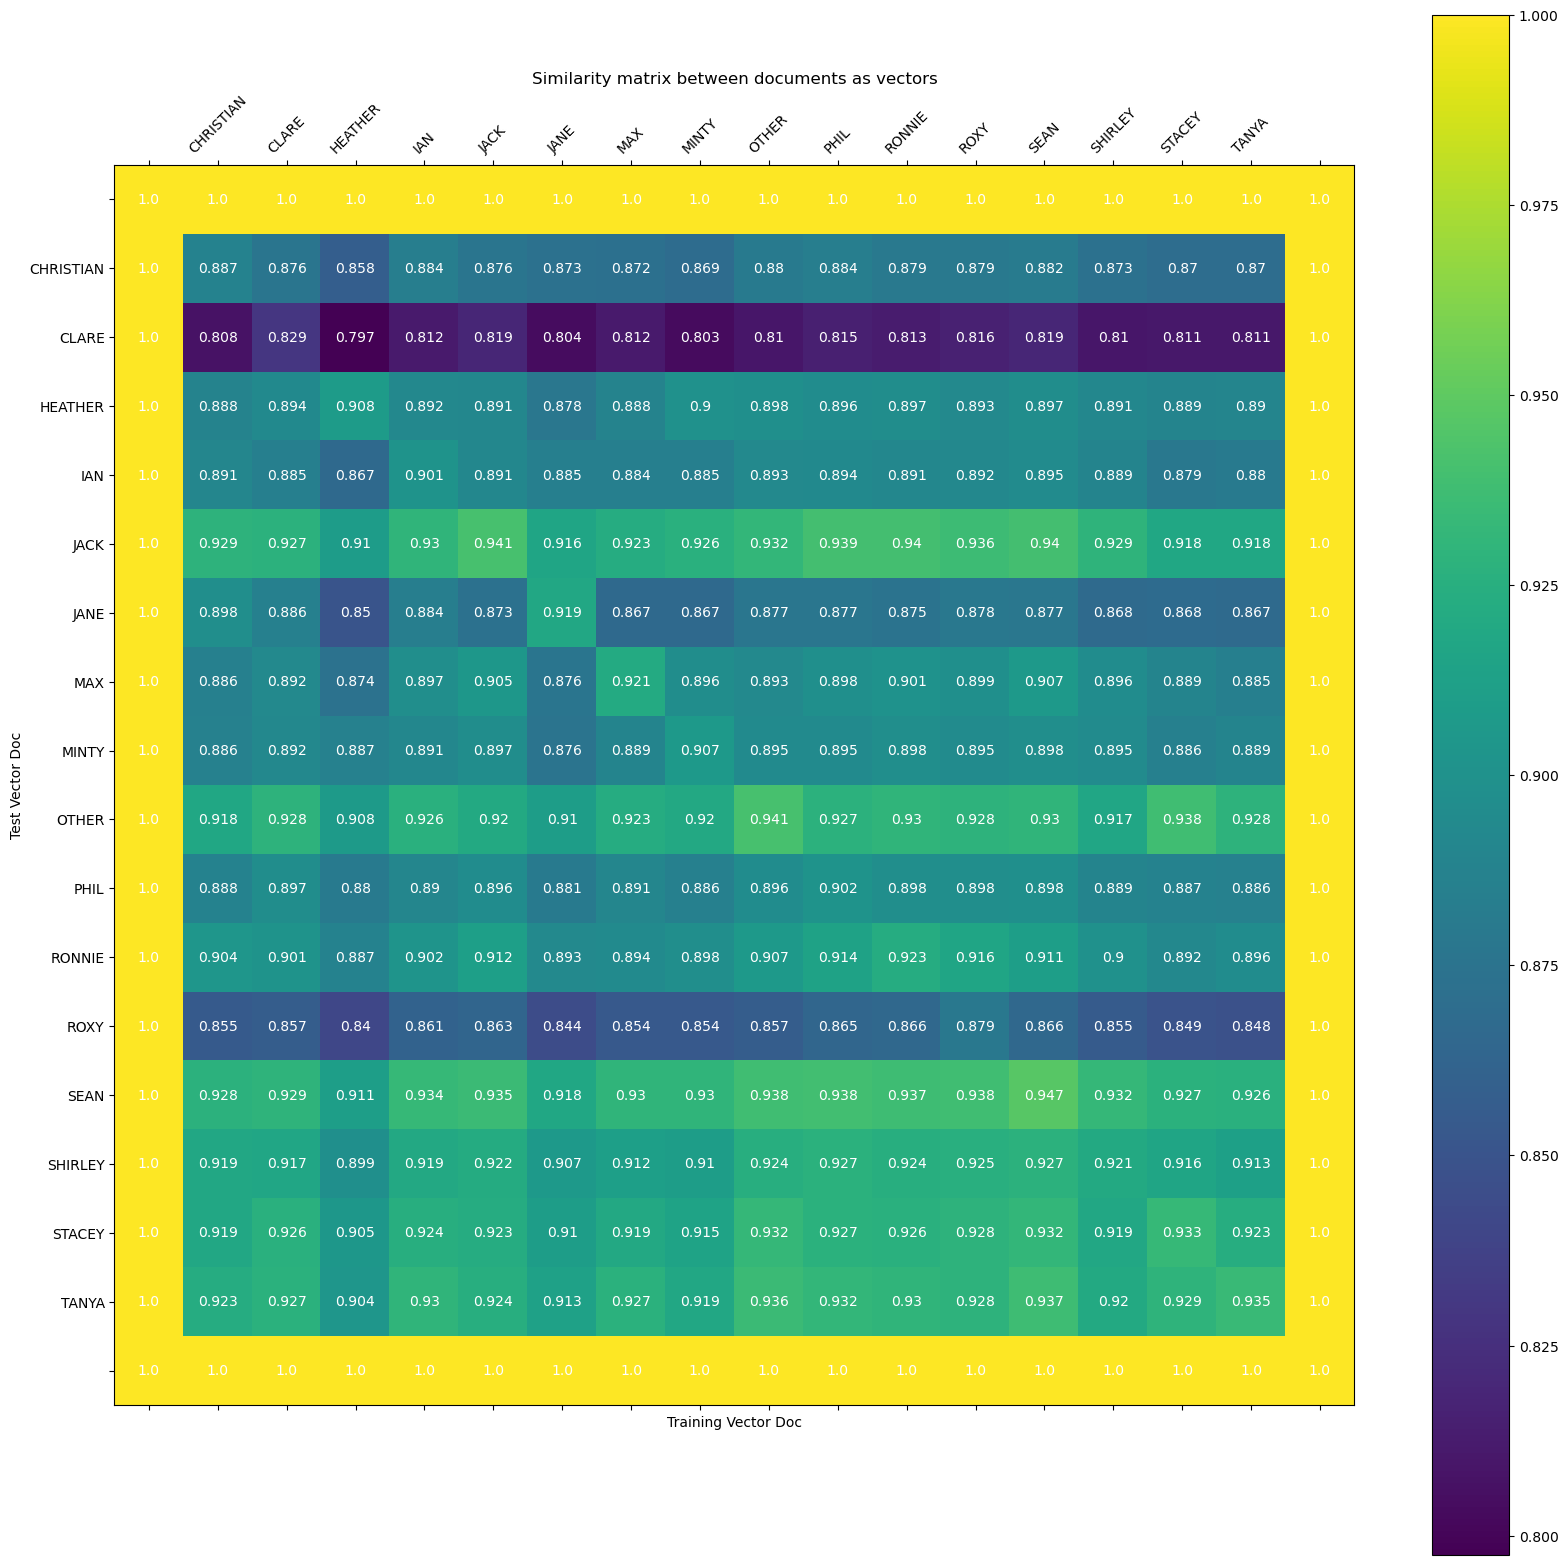

In [62]:
# Validation Similarity Heatmap
print("="*70)
print("Validation Similarity Heatmap")
print("="*70)
plot_heat_map_similarity(df_val)

In [63]:
# Q4 Analysis Stage 
print("\n" + "="*70)
print("Q4: Analysing Similarity Results")
print("="*70)

# Identify closest non-self matches
print("(Closest Non-self Matches)")

def find_closest_non_self_matches(df, top_n=3):
    """
    For each character find the other closest matching training characters (exluding the character him/herself)
    """
    results = []
    test_characters = sorted(df['doc1'].unique())
    for test_char in test_characters:
        # Get all similarities for this test character
        char_sims = df[df['doc1'] == test_char].copy()
        # Exclude self matches
        char_sims = char_sims[char_sims['doc2'] != test_char]
        # Sort by similarity from highest to lowest
        char_sims = char_sims.sort_values('similarity', ascending=False)
        # Get top number of closest non-self matches 
        for rank, row in enumerate(char_sims.head(top_n).itertuples(), 1):
            results.append({
                'test_character': test_char,
                'rank': rank,
                'most_matching_characters': row.doc2,
                'similarity': row.similarity,
                'self_similarity': df[(df['doc1'] == test_char) & (df['doc2'] == test_char)]['similarity'].values[0]
            })
    return pd.DataFrame(results)

closest_matches = find_closest_non_self_matches(df_val, top_n=3)

# Display all the results
for test_char in sorted(df_val['doc1'].unique()):
    char_matches = closest_matches[closest_matches['test_character'] == test_char]
    self_sim = char_matches.iloc[0]['self_similarity']

    print(f"\n{test_char}'s Self Similarity: {self_sim:.3f}")
    print("\n")
    for _, row in char_matches.iterrows():
        print(f" {row['rank']}. Most similar to {row['most_matching_characters']:10s}")
        print(f"\n Similarity Score: {row['similarity']:.3f}")
        print("\n")
        
    # Check if the character him/herself is the best match to him/herself
    if char_matches.iloc[0]['similarity'] > self_sim:
        print(f"\nWarning! There might be a mismatch: {test_char} is more similar to {char_matches.iloc[0]['most_matching_characters']} than to the character itself")


Q4: Analysing Similarity Results
(Closest Non-self Matches)

CHRISTIAN's Self Similarity: 0.887


 1. Most similar to IAN       

 Similarity Score: 0.884


 2. Most similar to PHIL      

 Similarity Score: 0.884


 3. Most similar to SEAN      

 Similarity Score: 0.882



CLARE's Self Similarity: 0.829


 1. Most similar to SEAN      

 Similarity Score: 0.819


 2. Most similar to JACK      

 Similarity Score: 0.819


 3. Most similar to ROXY      

 Similarity Score: 0.816



HEATHER's Self Similarity: 0.908


 1. Most similar to MINTY     

 Similarity Score: 0.900


 2. Most similar to OTHER     

 Similarity Score: 0.898


 3. Most similar to RONNIE    

 Similarity Score: 0.897



IAN's Self Similarity: 0.901


 1. Most similar to SEAN      

 Similarity Score: 0.895


 2. Most similar to PHIL      

 Similarity Score: 0.894


 3. Most similar to OTHER     

 Similarity Score: 0.893



JACK's Self Similarity: 0.941


 1. Most similar to SEAN      

 Similarity Score: 0.940



In [64]:
# Identify the furthest matches 
print("(Find the Furthest Matches)")

def find_furthest_matches(df, top_n=3):
    """
    Find the most different character pairs
    """
    results = []
    test_characters = sorted(df['doc1'].unique())
    for test_char in test_characters:
        # Get all similar characters for this test character
        char_sims = df[df['doc1'] == test_char]. copy()
        # Sort characters by lowest similarity 
        char_sims = char_sims.sort_values('similarity', ascending=True)
        # Get top_n for finding furthest matches 
        for rank, row in enumerate(char_sims.head(top_n).itertuples(), 1):
            results.append({
                'test_character': test_char,
                'rank': rank,
                'furthest_from': row.doc2,
                'similarity': row.similarity,
            })
    return pd.DataFrame(results)
furthest_matches = find_furthest_matches(df_val, top_n=3)

# Display all the results
for test_char in sorted(df_val['doc1'].unique()):
    char_matches = furthest_matches[furthest_matches['test_character'] == test_char]
    self_sim = char_matches.iloc[0]['similarity']

    print(f"\n{test_char}'s Self Similarity: {self_sim:.3f}")
    print("\n")
    for _, row in char_matches.iterrows():
        print(f"{row['rank']}. Least Similar to {row['furthest_from']:.10s}")
        print(f"\n Similarity Score: {row['similarity']:.3f}")

(Find the Furthest Matches)

CHRISTIAN's Self Similarity: 0.858


1. Least Similar to HEATHER

 Similarity Score: 0.858
2. Least Similar to MINTY

 Similarity Score: 0.869
3. Least Similar to STACEY

 Similarity Score: 0.870

CLARE's Self Similarity: 0.797


1. Least Similar to HEATHER

 Similarity Score: 0.797
2. Least Similar to MINTY

 Similarity Score: 0.803
3. Least Similar to JANE

 Similarity Score: 0.804

HEATHER's Self Similarity: 0.878


1. Least Similar to JANE

 Similarity Score: 0.878
2. Least Similar to MAX

 Similarity Score: 0.888
3. Least Similar to CHRISTIAN

 Similarity Score: 0.888

IAN's Self Similarity: 0.867


1. Least Similar to HEATHER

 Similarity Score: 0.867
2. Least Similar to STACEY

 Similarity Score: 0.879
3. Least Similar to TANYA

 Similarity Score: 0.880

JACK's Self Similarity: 0.910


1. Least Similar to HEATHER

 Similarity Score: 0.910
2. Least Similar to JANE

 Similarity Score: 0.916
3. Least Similar to STACEY

 Similarity Score: 0.918

JANE's S

In [65]:
# Analysis on the mismatches
print("(Analysing the MisMatches)")

def analyse_mismatch(test_char, train_char, val_corpus, train_corpus):
    """
    Analyse why test_char is similar to train_char when they shouldn't be similar
    """
    # Find the train char data
    train_data = next((tokens, features) for name, tokens, features in train_corpus if name == train_char)
    # Find the test char data
    test_data = next((tokens, features) for name, tokens, features in val_corpus if name == test_char)

    train_tokens, train_feats = train_data
    test_tokens, test_feats = test_data

    print(f"Why is {test_char} (test character) similar to {train_char} (train character)?")
    print("="*70)

    # 1. Word overlapping analysis 
    train_vocab = set(t for t in train_tokens if not t.startswith('_'))
    test_vocab = set(t for t in test_tokens if not t.startswith('_'))

    shared_words = train_vocab & test_vocab
    overlap_ratio = len(shared_words) / len(train_vocab | test_vocab)

    print("\n1. Vocabulary Overlap: ")
    print(f" - {train_char} has {len(train_vocab)} unique words")
    print(f" - {test_char} has {len(test_vocab)} unique words")
    print(f"Shared Words: {len(shared_words)} ({overlap_ratio:.1%}overlap)")

    # Show most common shared words 
    train_counter = Counter(train_tokens)
    test_counter = Counter(test_tokens)

    shared_word_counts = [(w, train_counter[w], test_counter[w]) for w in shared_words if train_counter[w] > 5]
    shared_word_counts.sort(key=lambda x : x[1] + x[2], reverse=True)

    print("\n Top 10 shared words: ")
    for word, train_count, test_count in shared_word_counts[:10]:
        print(f" - {word}: {train_char}={train_count}, {test_char}={test_count}")
    # 2. linguistics  similarity analysis
    print("\n2. Linguistic Similarity Analysis and Comparison: ")
    # Compare stylomrtric features
    for feat_name in ['vocabulary_richness', 'avg_word_length', 'avg_sentence_length']:
        if f"Feature_{feat_name}" in train_feats and f"Feature_{feat_name}" in test_feats:
            train_val = train_feats[f"Feature_{feat_name}"]
            test_val = test_feats[f"Feature_{feat_name}"]
            diff = abs(train_val - test_val)
            print(f" - {feat_name:25s}: {train_char}={train_val:.3f}, {test_char}={test_val:.3f}, diff = {diff:.3f}")
            
    # Compare punctuation features
    print("\n3. Punctuation Features Analysis:")
    for feat_name in ['exclamation_ratio', 'question_ratio', 'ellipsis_ratio']:
        if f"Feature_{feat_name}" in train_feats and f"Feature_{feat_name}" in test_feats:
            train_val = train_feats[f"Feature_{feat_name}"]
            test_val = test_feats[f"Feature_{feat_name}"]
            diff = abs(train_val - test_val)
            print(f" - {feat_name:25s}: {train_char}={train_val:.3f}, {test_char}={test_val:.3f}, diff = {diff:.3f}")

    # Compare POS features
    print("\n4. Grammatical Patterns and Part-of-Speech Feature Analysis:")
    for feat_name in ['noun_ratio', 'verb_ratio', 'adj_ratio']:
        if f"Feature_{feat_name}" in train_feats and f"Feature_{feat_name}" in test_feats:
            train_val = train_feats[f"Feature_{feat_name}"]
            test_val = test_feats[f"Feature_{feat_name}"]
            diff = abs(train_val - test_val)
            print(f" - {feat_name:25s}: {train_char}={train_val:.3f}, {test_char}={test_val:.3f}, diff = {diff:.3f}")
            
    print("\n"+"="*70)

# Identify characters with mismatches, where the character him/herself is not ranked first
print("\n Analysing mismatches in detail...\n")

for test_char in sorted(df_val['doc1'].unique()):
    # Get similarity of self compared to the best of non-self characters 
    self_sim = df_val[(df_val['doc1'] == test_char) & (df_val['doc2'] == test_char)]['similarity'].values[0]
    non_self = df_val[(df_val['doc1'] == test_char) & (df_val['doc2'] != test_char)]
    best_non_self = non_self.sort_values('similarity', ascending=False).iloc[0]
    # If best non-self character has more similarity than the test character him/herself then analyse it
    if best_non_self['similarity'] > self_sim:
        print(f"\nWarning! Mismatch Detected: {test_char}")
        print(f"Self Similarity: {self_sim:.3f}")
        print(f"Best non-self similarity: {best_non_self['doc2']} -> Similarity Score: {best_non_self['similarity']:.3f}")

        # Detailed analysis using the function
        analyse_mismatch(test_char, best_non_self['doc2'], val_corpus_with_features, training_corpus_with_features)

(Analysing the MisMatches)

 Analysing mismatches in detail...


Warning! Mismatch Detected: SHIRLEY
Self Similarity: 0.921
Best non-self similarity: SEAN -> Similarity Score: 0.927
Why is SHIRLEY (test character) similar to SEAN (train character)?

1. Vocabulary Overlap: 
 - SEAN has 495 unique words
 - SHIRLEY has 171 unique words
Shared Words: 86 (14.8%overlap)

 Top 10 shared words: 
 - ...: SEAN=30, SHIRLEY=3
 - na: SEAN=16, SHIRLEY=3
 - well: SEAN=16, SHIRLEY=3
 - yeah: SEAN=17, SHIRLEY=1
 - get: SEAN=16, SHIRLEY=2
 - like: SEAN=17, SHIRLEY=1
 - got: SEAN=14, SHIRLEY=3
 - think: SEAN=14, SHIRLEY=3
 - gon: SEAN=14, SHIRLEY=2
 - would: SEAN=11, SHIRLEY=5

2. Linguistic Similarity Analysis and Comparison: 

3. Punctuation Features Analysis:

4. Grammatical Patterns and Part-of-Speech Feature Analysis:


Warning! Mismatch Detected: TANYA
Self Similarity: 0.935
Best non-self similarity: SEAN -> Similarity Score: 0.937
Why is TANYA (test character) similar to SEAN (train character)?

1

In [67]:
# Feature Importance Analysis 
print("(Feature Importance Analysis)")

def analyze_top_features_per_character(corpus_with_features, top_n=15):
    """
    Show the most distinctive features for each character.
    """
    feature_names = corpusVectorizer.get_feature_names_out()
    tfidf_matrix = training_feature_matrix.toarray()
    
    print("\nTop distinctive features per character:")
    print("=" * 70)
    
    for idx, (name, tokens, feats) in enumerate(corpus_with_features):
        char_tfidf = tfidf_matrix[idx]
        
        # Get top features
        top_indices = np.argsort(char_tfidf)[-top_n:][::-1]
        
        print(f"\n{name}:")
        print("-" * 50)
        
        for rank, feat_idx in enumerate(top_indices, 1):
            feat_name = feature_names[feat_idx]
            feat_value = char_tfidf[feat_idx]
            
            # Categorize feature
            if feat_name.startswith('Feature_'):
                feat_type = "Linguistic"
                display_name = feat_name.replace('Feature_', '')
            elif '_' in feat_name and not feat_name.startswith('_'):
                feat_type = "Bigram"
                display_name = feat_name
            else:
                feat_type = "Word"
                display_name = feat_name
            
            print(f"  {rank:2d}. [{feat_type:12s}] {display_name:30s} (TF-IDF: {feat_value:.4f})")

analyze_top_features_per_character(training_corpus_with_features, top_n=15)

(Feature Importance Analysis)

Top distinctive features per character:

CHRISTIAN:
--------------------------------------------------
   1. [Word        ] _eol_                          (TF-IDF: 0.6793)
   2. [Linguistic  ] utterance_count                (TF-IDF: 0.6793)
   3. [Word        ] ian                            (TF-IDF: 0.1063)
   4. [Word        ] jane                           (TF-IDF: 0.0715)
   5. [Word        ] ...                            (TF-IDF: 0.0566)
   6. [Word        ] 's                             (TF-IDF: 0.0475)
   7. [Word        ] yeah                           (TF-IDF: 0.0340)
   8. [Word        ] get                            (TF-IDF: 0.0317)
   9. [Word        ] like                           (TF-IDF: 0.0317)
  10. [Word        ] got                            (TF-IDF: 0.0294)
  11. [Word        ] would                          (TF-IDF: 0.0294)
  12. [Word        ] good                           (TF-IDF: 0.0288)
  13. [Word        ] plumber          

In [68]:
#
print("Saving Analysis to Files...")
# Save closest matches
closest_matches.to_csv('q4_closest_matches.csv', index=False)

# Save furthest matches
furthest_matches.to_csv('q4_furthest_matches.csv', index=False)

print("\n" + "="*70)
print("Q4 Analysis and Saving is Complete!")
print("Results saved to:")
print("  - q4_closest_matches.csv")
print("  - q4_furthest_matches.csv")
print("="*70)

Saving Analysis to Files...

Q4 Analysis and Saving is Complete!
Results saved to:
  - q4_closest_matches.csv
  - q4_furthest_matches.csv


Final Evaluation
Training Starting For Training Set...
lines per character: 
CHRISTIAN: 300 lines
CLARE: 300 lines
HEATHER: 300 lines
IAN: 300 lines
JACK: 300 lines
JANE: 300 lines
MAX: 300 lines
MINTY: 300 lines
OTHER: 300 lines
PHIL: 300 lines
RONNIE: 300 lines
ROXY: 300 lines
SEAN: 300 lines
SHIRLEY: 300 lines
STACEY: 300 lines
TANYA: 300 lines
Preprocessing: CHRISTIAN
Character Trigrams: 2565 unique trigrams

Preprocessing: CLARE
Character Trigrams: 2526 unique trigrams

Preprocessing: HEATHER
Character Trigrams: 2348 unique trigrams

Preprocessing: IAN
Character Trigrams: 2626 unique trigrams

Preprocessing: JACK
Character Trigrams: 2487 unique trigrams

Preprocessing: JANE
Character Trigrams: 2391 unique trigrams

Preprocessing: MAX
Character Trigrams: 2513 unique trigrams

Preprocessing: MINTY
Character Trigrams: 2340 unique trigrams

Preprocessing: OTHER
Character Trigrams: 2077 unique trigrams

Preprocessing: PHIL
Character Trigrams: 2281 unique trigrams

Preprocessing: RONNIE

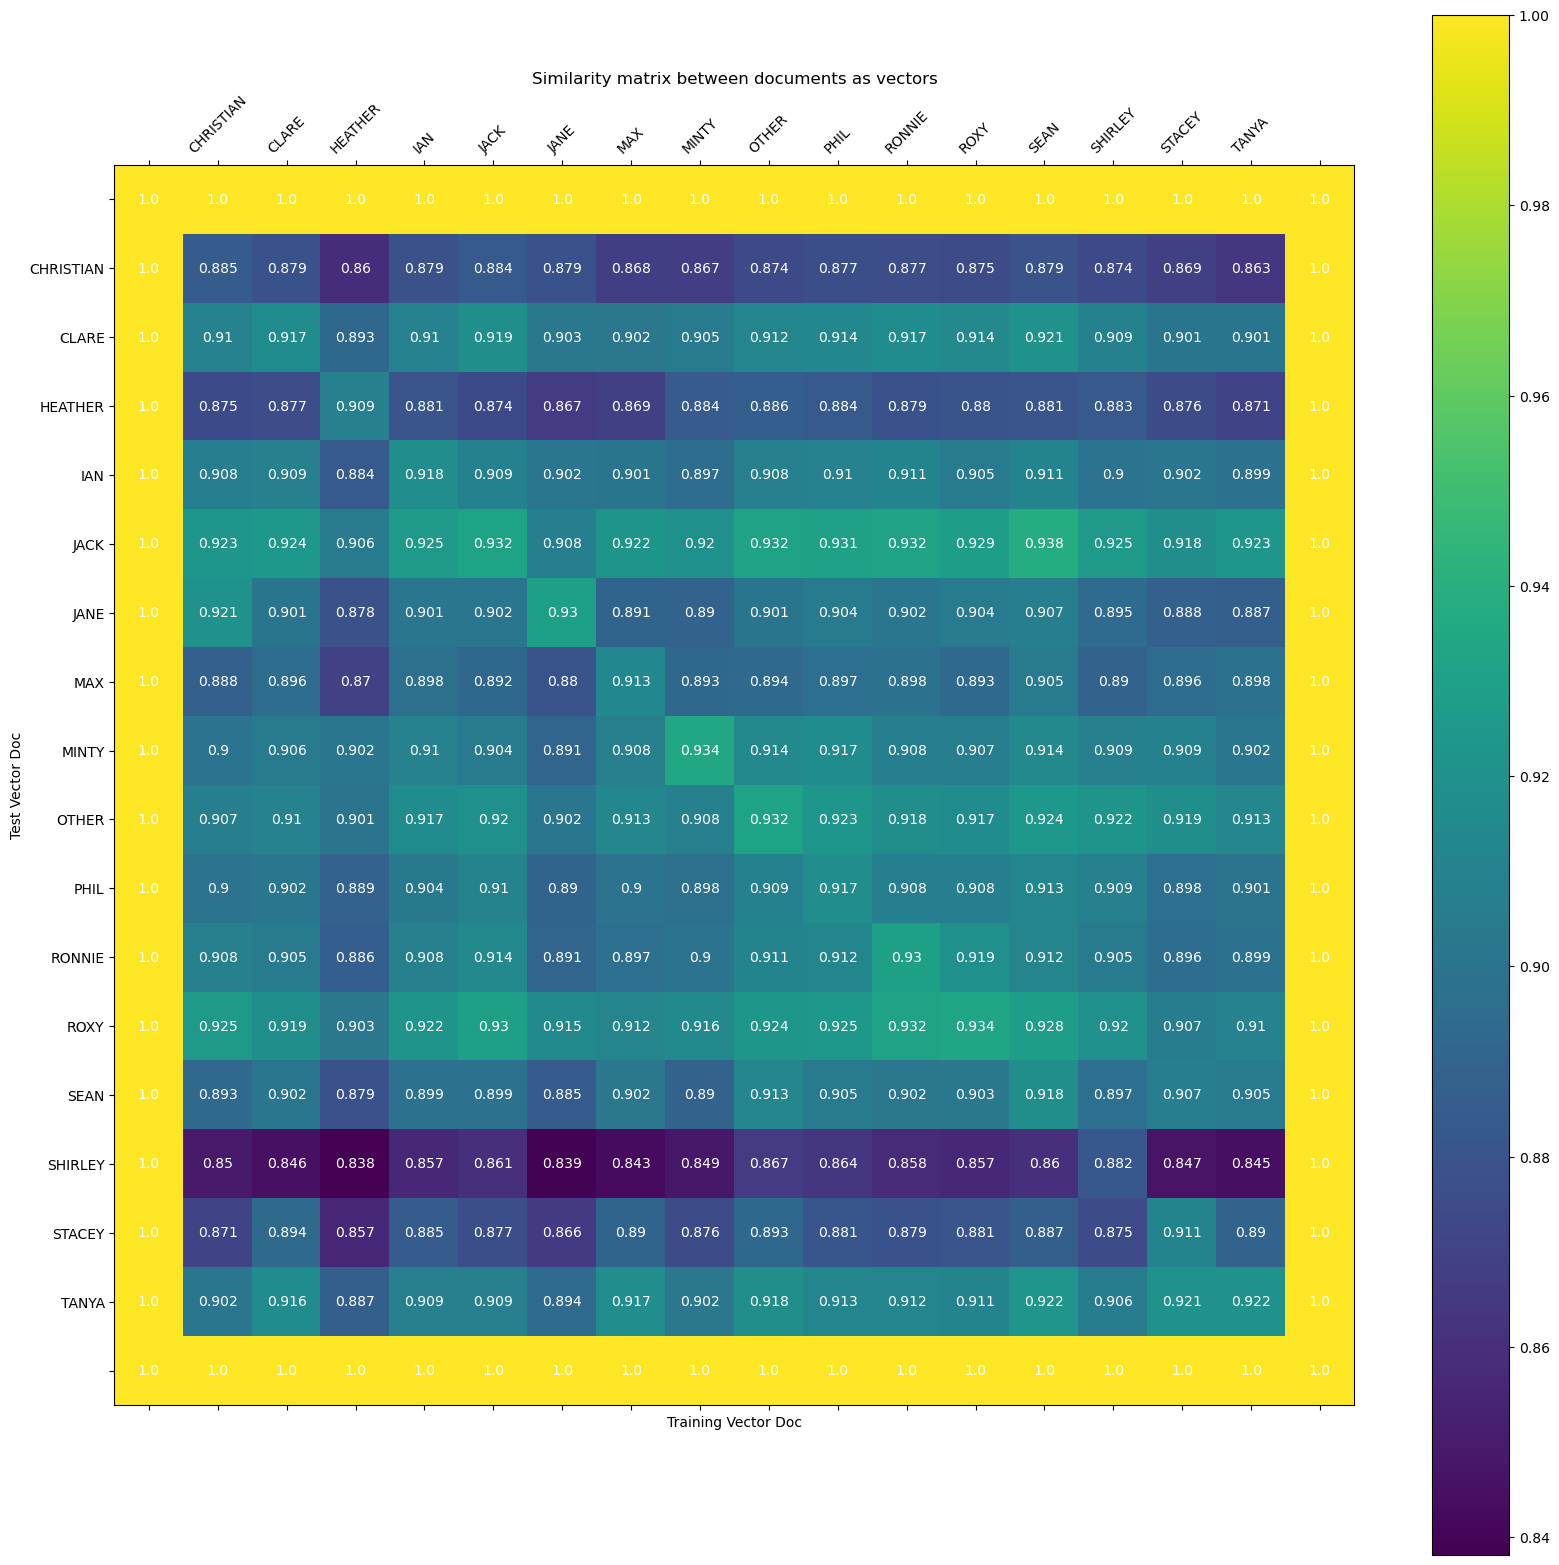

In [69]:
# ===== Test Stage - Final Evalutation =====
print("="*70)
print("Final Evaluation")
print("="*70)

print("Training Starting For Training Set...")

# Recreate training process with 300 lines
train_character_docs = create_character_document_from_dataframe(train_data, max_line_count=300)

training_corpus_with_features = []
for name in sorted(train_character_docs.keys()):
    char_data = train_character_docs[name]
    print(f"Preprocessing: {name}")
    
    # Get original text (before preprocessing) for some features
    original_text = char_data['text']
    lines_list = char_data['lines']
    
    # Preprocess the text with the predefined pre_process() function
    processed_tokens = pre_process_configurable(original_text, best_q1_config)
    
    # Extracting all advanced or extra features
    extra_features = {}
    
    # Use best extra features config from Q2
    extra_features = extract_features_configurable(original_text, lines_list, processed_tokens, best_q2_config)
    
    # Store processed tokens with the new extra features in a corpus
    training_corpus_with_features.append((name, processed_tokens, extra_features))
    print()
    
# Extract labels from training data as the training labels
train_labels = [name for name, doc, features in training_corpus_with_features]

# Create training feature matrix if (fitting = True) to learn vocabularies
# Update create_document_matrix_from_corpus (basic) to use create_document_matrix_with_features function (advance) for Q2
training_feature_matrix = create_document_matrix_with_features(training_corpus_with_features, fitting=True)


print(f"\n{'='*70}")
print("Extracting Extra Features For Test Set")
print(f"\n{'='*70}")

# Create testing corpus with 50 lines 
test_character_docs = create_character_document_from_dataframe(test_data, max_line_count=50)

test_corpus_with_features = []
for name in sorted(test_character_docs.keys()):
    char_data = test_character_docs[name]
    print(f"Preprocessing: {name}")
    
    # Get original text (before preprocessing) for some features
    original_text = char_data['text']
    lines_list = char_data['lines']
    
    # Preprocess the text with the predefined pre_process() function
    processed_tokens = pre_process_configurable(original_text, best_q1_config)
    
    # Extracting all advanced or extra features
    extra_features = {}
    
    # Use best extra features config from Q2
    extra_features = extract_features_configurable(original_text, lines_list, processed_tokens, best_q2_config)
    
    # Store processed tokens with the new extra features in a corpus
    test_corpus_with_features.append((name, processed_tokens, extra_features))
    print()
    
# Extract labels from testing data as the testing labels
test_labels = [name for name, doc, features in test_corpus_with_features]

# Just transform the test_feature_matrix, don't fit to use previous learned vocab as it was only for test set
test_feature_matrix = create_document_matrix_with_features(test_corpus_with_features, fitting=False)

# Final Evaluation
print("="*70)
print("Final Evaluation Results")
print("="*70)

mean_rank_test, mean_cosine_simliarity_test, acc_test, df_test = compute_IR_evaluation_scores(training_feature_matrix, test_feature_matrix, train_labels, test_labels)

# Test Similarity Heatmap
print("="*70)
print("Test Similarity Heatmap")
print("="*70)
plot_heat_map_similarity(df_test)

# Q1. Improve pre-processing (20 marks)
Using the pre-processing techniques you have learned in the module, improve the `pre_process` function above, which currently just tokenizes text based on white space.

When developing, use the first 300 and 50 lines from the training and validation files, as per above. To check the improvements by using the different techniques, use the `compute_IR_evaluation_scores` function as above. The **mean rank** is the main metric you need to focus on improving throughout this assignment, where the target/best possible performance is **1** (i.e. all test/validation data character documents are closest to their corresponding training data character documents) and the worst is **16**. Initially, the code in this template achieves a mean rank of **4.3**  and accuracy of **0.25** on the test set and a mean rank of **3.6** and accuracy of **0.31** on the validation set - you should be looking to improve those, particularly getting the mean rank as close to 1 as possible.


# Q2. Improve advanced feature extraction with Gen AI (45 marks)
Chat with Gen AI, such as GPT and Gemini, to come up with solutions for advanced feature extraction that can further improve the performance. Discuss in the report what strategies you used to prompt the Gen AI to help you with the ideas and what you've learned and implemented from the conversation, as well as what the Gen AI's limitations are. You are **ONLY** allowed to chat with Gen AI to come up with ideas. You **MUST** write the code by yourself.  You **MUST** output the full chat history between you and Gen AI and submit it as a separate PDF file; failure to submit the Gen AI history will result in a **0 mark** for this question. 

# Q3. Parameter Search (15 marks)
It is a good practice to conduct a systematic parameter search instead of a random search as this will give you more 
reliable results. Given the scope of this assignment, it is possible to conduct a **grid search** on options you decided to try within the individual questions. The grid search should be done within the individual questions (i.e. Q1-Q2), and the later question should adopt the best settings from the previous questions. 

# Q4. Analyse the similarity results (10 marks)
From your system so far run on the training/validation sets, identify the heldout character vectors ranked closest to each character's training vector which are not the character themselves, and those furthest away, as displayed using the `plot_heat_map_similarity` function. In your report, try to ascribe reasons why this is the case, particularly for those where there isn't a successful highest match between the target character in the training set and that character's vector in the heldout set yet. Observations you could make include how their language use is similar, resulting in similar word or ngram features.

# Q5. Run on final test data  (10 marks)
Test your best system using the code below to train on the training data (using the first 300 lines per character maximum) and do the final testing on the test file (using the first 50 lines per character maximum).

Make any necessary adjustments such that it runs in the same way as the training/testing regime you developed above- e.g. making sure any transformer objects are initialized before `create_document_matrix_from_corpus` is called. Make sure your best system is left in the notebook and it is clear what the mean rank and accuracy of document selection are on the test data.

In [70]:
# ============================================================================
# PERFORMANCE COMPARISON SUMMARY
# ============================================================================

print(f"\n{'='*70}")
print("PERFORMANCE SUMMARY")
print(f"{'='*70}\n")

print("BASELINE (from coursework brief):")
print("  Validation - Mean Rank: 3.60, Accuracy: 0.31")
print("  Test       - Mean Rank: 4.30, Accuracy: 0.25")
print()
print("MY RESULTS:")
print(f"  Validation - Mean Rank: {mean_rank_val:.2f}, Accuracy: {acc_val:.2%}")
print(f"  Test       - Mean Rank: {mean_rank_test:.2f}, Accuracy: {acc_test:.2%}")
print()
print("IMPROVEMENT:")
print(f"  Validation - Mean Rank: {3.60 - mean_rank_val:+.2f}, Accuracy: {acc_val - 0.31:+.2%}")
print(f"  Test       - Mean Rank: {4.30 - mean_rank_test:+.2f}, Accuracy: {acc_test - 0.25:+.2%}")


PERFORMANCE SUMMARY

BASELINE (from coursework brief):
  Validation - Mean Rank: 3.60, Accuracy: 0.31
  Test       - Mean Rank: 4.30, Accuracy: 0.25

MY RESULTS:
  Validation - Mean Rank: 1.50, Accuracy: 87.50%
  Test       - Mean Rank: 1.25, Accuracy: 81.25%

IMPROVEMENT:
  Validation - Mean Rank: +2.10, Accuracy: +56.50%
  Test       - Mean Rank: +3.05, Accuracy: +56.25%
